# Hussain Ali Al Sabah - 2230005429

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import re
from pathlib import Path

import pandas as pd
import torch
from torch import nn
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")  
import matplotlib.pyplot as plt
from IPython.display import display

torch.manual_seed(42)
torch.set_num_threads(1)  

## Step 2 — Upload the dataset

In [2]:
dataset_path = Path("Lab_11_QnA_Dataset.csv")
if not dataset_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {dataset_path.resolve()}\n"
        "Place Lab_11_QnA_Dataset.csv in the notebook's working directory "
        "or change dataset_path to its actual location, then rerun this cell."
    )

df = pd.read_csv(dataset_path)
required_columns = {"question", "answer_id"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required CSV columns: {sorted(missing_columns)}")

df = df.dropna(subset=["question", "answer_id"]).reset_index(drop=True)
df["question"] = df["question"].astype(str).str.strip()
df = df[df["question"].ne("")].reset_index(drop=True)
if df.empty:
    raise ValueError("The CSV contains no valid questions and answer IDs.")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation using the same tokenization function for training and charts.
2. Give each word a number (0 is reserved for padding, 1 for unknown words).
3. Pad questions with zeros to the same length.
4. Convert answer IDs to consecutive class indices for PyTorch cross-entropy.

**No TensorFlow installation is needed.**

Preprocessing uses standard Python and PyTorch, avoiding TensorFlow / protobuf compatibility errors.

In [3]:

def tokenize(text):
    return re.findall(r"[a-z0-9]+(?:'[a-z0-9]+)?", str(text).lower())


question_tokens = [tokenize(question) for question in df["question"]]
if any(len(tokens) == 0 for tokens in question_tokens):
    raise ValueError("One or more questions have no usable word tokens.")

vocab = {"<PAD>": 0, "<UNK>": 1}
for tokens in question_tokens:
    for token in tokens:
        if token not in vocab:
            vocab[token] = len(vocab)

max_len = max(map(len, question_tokens))
sequences = [[vocab.get(word, 1) for word in tokens] for tokens in question_tokens]
X = torch.tensor([seq + [0] * (max_len - len(seq)) for seq in sequences], dtype=torch.long)


answer_ids = df["answer_id"].unique().tolist()
answer_to_class = {answer_id: i for i, answer_id in enumerate(answer_ids)}
y = torch.tensor([answer_to_class[answer_id] for answer_id in df["answer_id"]], dtype=torch.long)
num_classes = len(answer_ids)

print(f"Input shape: {tuple(X.shape)} | Vocabulary size: {len(vocab)} | Classes: {num_classes}")

Input shape: (168, 11) | Vocabulary size: 228 | Classes: 12


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self, vocab_size, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, 16, padding_idx=0)
        
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, num_classes)

    def forward(self, tokens):
        embedded = self.emb(tokens)                 
        hidden, _ = self.rnn(embedded)              
        scores = self.att(hidden).squeeze(-1)        
       
        scores = scores.masked_fill(tokens.eq(0), float("-inf"))
        weights = torch.softmax(scores, dim=1)      
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNN(vocab_size=len(vocab), num_classes=num_classes)

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
model.train()

for epoch in range(50):
    optimizer.zero_grad()  
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:02d}/50 | Training loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
    logits, _ = model(X)
    train_accuracy = (logits.argmax(dim=1) == y).float().mean().item()
print(f"Training finished! Training accuracy: {train_accuracy:.1%}")

Epoch 10/50 | Training loss: 1.8328
Epoch 20/50 | Training loss: 0.9532
Epoch 30/50 | Training loss: 0.3626
Epoch 40/50 | Training loss: 0.1231
Epoch 50/50 | Training loss: 0.0484
Training finished! Training accuracy: 99.4%


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

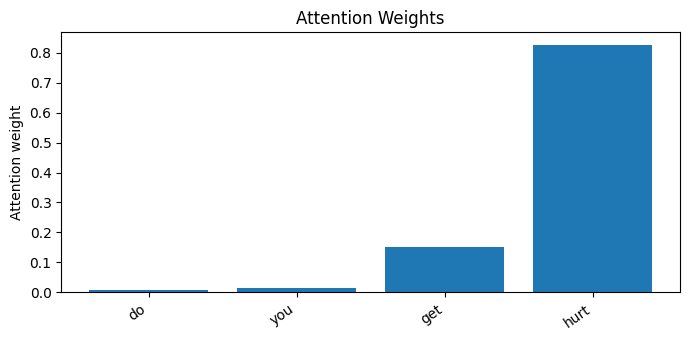

Highest-attention word: hurt


In [6]:

idx = 0
words = question_tokens[idx]

model.eval()
with torch.no_grad():
    prediction, weights = model(X[idx:idx+1])

scores = weights[0, :len(words)].tolist()
plt.figure(figsize=(max(7, len(words) * 0.7), 3.5))
plt.bar(range(len(words)), scores)
plt.xticks(range(len(words)), words, rotation=35, ha="right")
plt.title("Attention Weights")
plt.ylabel("Attention weight")
plt.tight_layout()
plt.show()
print("Highest-attention word:", words[max(range(len(scores)), key=lambda i: scores[i])])

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: Do you get hurt?
Highest attention word: hurt
Content word — may represent the main meaning
Highest attention content word: hurt

Question: Are you old?
Highest attention word: old
Content word — may represent the main meaning
Highest attention content word: old

Question: Will you ask me anything about myself
Highest attention word: anything
Content word — may represent the main meaning
Highest attention content word: anything



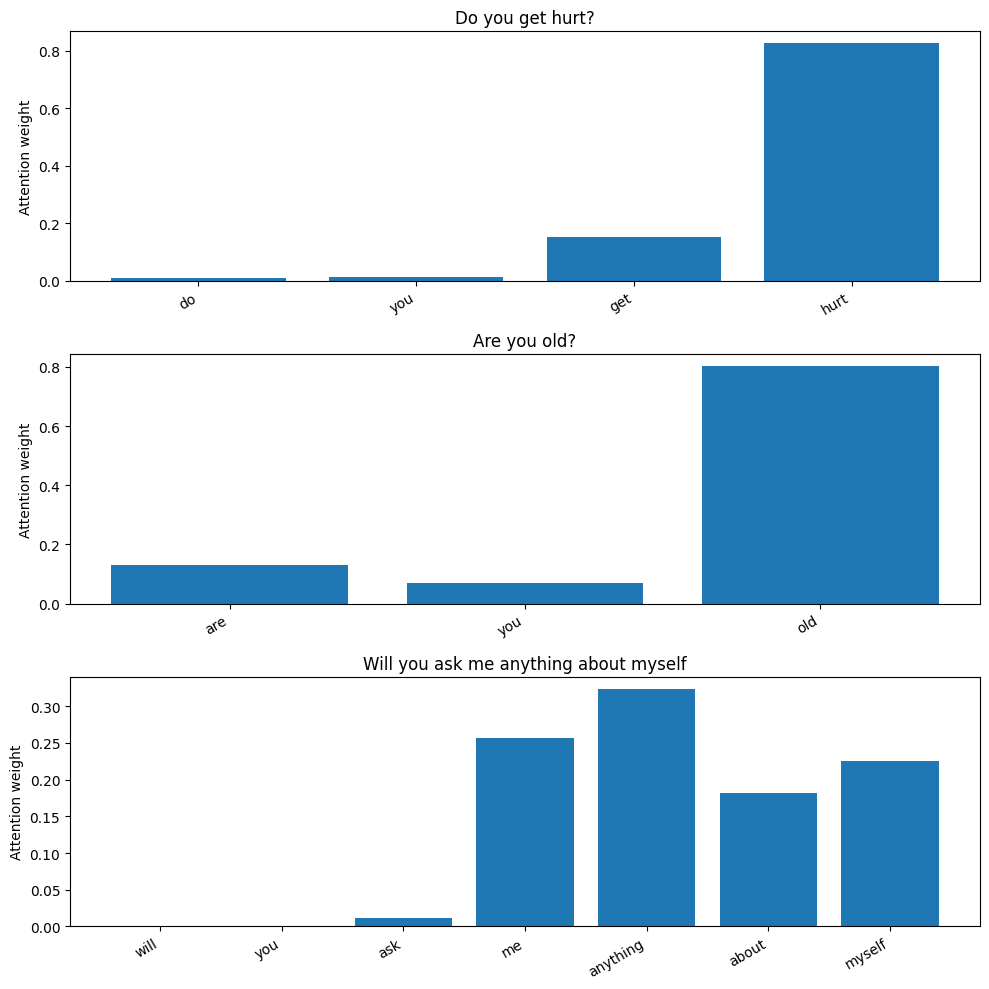

In [7]:
# Task 1 — Visualize 3 questions from different answer groups.
question_indices = df.drop_duplicates(subset="answer_id").index[:3].tolist()
if len(question_indices) < 3:
    raise ValueError("Task 1 needs at least 3 different answer groups.")

function_words = {"a", "an", "the", "and", "or", "to", "in", "on", "of", "about",
                  "do", "does", "did", "is", "are", "am", "be", "you",
                  "your", "i", "we", "can", "could", "would", "have", "has"}

fig, axes = plt.subplots(3, 1, figsize=(10, 10))
model.eval()
for ax, idx in zip(axes, question_indices):
    question = df.loc[idx, "question"]
    words = question_tokens[idx]

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    scores = weights[0, :len(words)].tolist()
    ax.bar(range(len(words)), scores)
    ax.set_xticks(range(len(words)), words, rotation=30, ha="right")
    ax.set_title(question)
    ax.set_ylabel("Attention weight")

    top_pos = max(range(len(scores)), key=lambda i: scores[i])
    top_word = words[top_pos]
    print(f"Question: {question}")
    print(f"Highest attention word: {top_word}")
    if top_word in function_words:
        print("Function word — not necessarily central to the meaning")
    else:
        print("Content word — may represent the main meaning")

    content_positions = [i for i, word in enumerate(words) if word not in function_words]
    if content_positions:
        top_content_pos = max(content_positions, key=lambda i: scores[i])
        print(f"Highest attention content word: {words[top_content_pos]}")
    print()

plt.tight_layout()
plt.show()

**Task 1 — Observations and answer**

The highest-attention words for the three questions were:

- **“Do you get hurt?”** — **hurt**
- **“Are you old?”** — **old**
- **“Will you ask me anything about myself”** — **anything**

Yes. In these examples, the highest-attention words are meaningful for understanding the questions. “Hurt” identifies the topic of being injured, “old” indicates age, and “anything” contributes to the meaning of the third question. The model therefore assigns high attention to informative words in these three cases. However, a high attention weight alone does not prove that a word is the most important one for understanding the sentence.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: How do you feel about artificial intelligence?
Highest attention word: about
Function word — not necessarily central to the meaning
Highest attention content word: intelligence

Question: What is your opinion about AI?
Highest attention word: ai
Content word — may represent the main meaning
Highest attention content word: ai



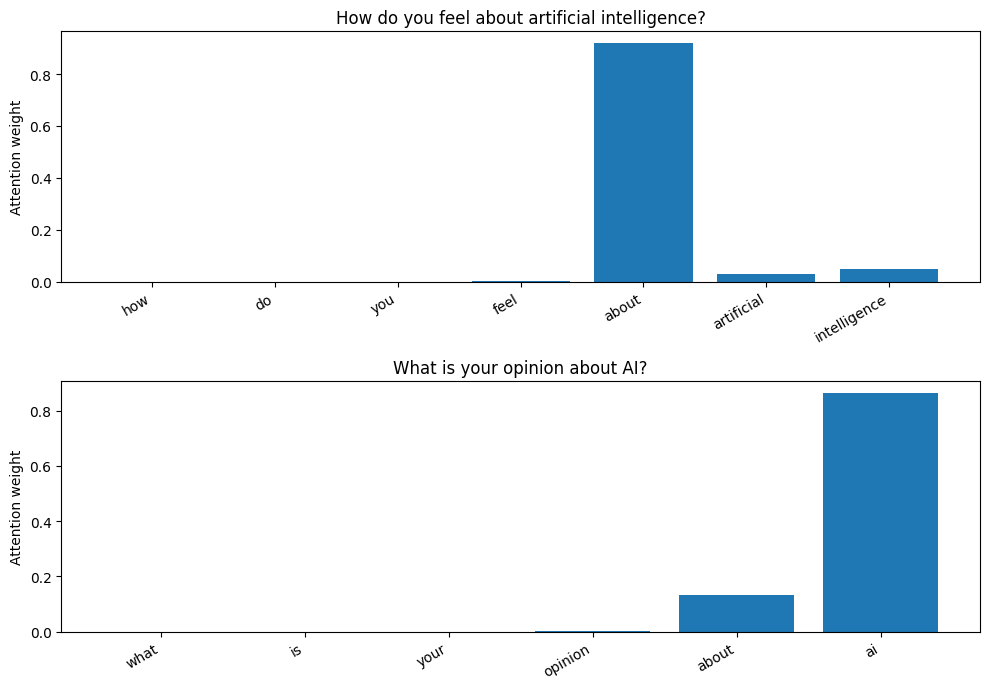

The questions have different highest-attention words.
Conclusion: Questions with the same answer_id can have different attention patterns.


In [8]:
# Task 2 — Compare two paraphrased questions from the actual dataset.
# Both questions ask about AI and have the same answer_id, but different wording.
pair_texts = ["How do you feel about artificial intelligence?", "What is your opinion about AI?"]
pair_indices = []
for text in pair_texts:
    matches = df.index[df["question"].str.strip().str.casefold().eq(text.casefold())].tolist()
    if matches:
        pair_indices.append(matches[0])
# Fallback if this notebook is rerun with another CSV.
if len(pair_indices) != 2:
    pair_indices = None
    for _, group in df.groupby("answer_id", sort=False):
        if len(group) >= 2:
            pair_indices = group.index[:2].tolist()
            break
if pair_indices is None:
    raise ValueError("Task 2 needs at least 2 questions with the same answer_id.")

function_words = {"a", "an", "the", "and", "or", "to", "in", "on", "of", "about",
                  "do", "does", "did", "is", "are", "am", "be", "you",
                  "your", "i", "we", "can", "could", "would", "have", "has"}

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
top_words = []
model.eval()
for ax, idx in zip(axes, pair_indices):
    question = df.loc[idx, "question"]
    words = question_tokens[idx]

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    scores = weights[0, :len(words)].tolist()
    ax.bar(range(len(words)), scores)
    ax.set_xticks(range(len(words)), words, rotation=30, ha="right")
    ax.set_title(question)
    ax.set_ylabel("Attention weight")

    top_pos = max(range(len(scores)), key=lambda i: scores[i])
    top_word = words[top_pos]
    top_words.append(top_word)
    print(f"Question: {question}")
    print(f"Highest attention word: {top_word}")

    if top_word in function_words:
        print("Function word — not necessarily central to the meaning")
    else:
        print("Content word — may represent the main meaning")

    content_positions = [i for i, word in enumerate(words) if word not in function_words]
    if content_positions:
        top_content_pos = max(content_positions, key=lambda i: scores[i])
        print(f"Highest attention content word: {words[top_content_pos]}")
    print()

plt.tight_layout()
plt.show()

if top_words[0] == top_words[1]:
    print("Both questions have the same highest-attention word.")
else:
    print("The questions have different highest-attention words.")
print("Conclusion: Questions with the same answer_id can have different attention patterns.")

**Task 2 — Observations and answer**

The two questions have similar meanings and both concern artificial intelligence, but their highest-attention words differ:

- **“How do you feel about artificial intelligence?”** — **about** (highest-attention content word: **intelligence**)
- **“What is your opinion about AI?”** — **ai**

The model focuses on **different highest-attention words** despite the similar meanings. In the first question, the largest weight falls on the function word “about,” while “intelligence” is the highest-weighted content word; in the second, it falls on “ai.” This illustrates that attention weights depend on the words and context of each input, rather than always highlighting identical words for similar questions. The similar topics of the two questions do not mean their attention patterns must match.